# 🔍 Anomaly Detection in Digital Payments — Fraud Pattern Discovery
### Full Pipeline: EDA → Outlier Analysis → K-Means → Hypothesis Testing → Logistic Regression → SVM

**Dataset:** [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud) by ULB on Kaggle

---
### Setup Instructions
**On Kaggle:** This notebook runs as-is. The dataset path is pre-configured.

**On Google Colab:**
1. Download `creditcard.csv` from the Kaggle link above
2. Upload it to your Colab session (Files panel on the left)
3. Change `DATA_PATH` in Cell 2 to `'creditcard.csv'`

## Cell 1 — Install & Import Libraries

In [1]:
# Install imbalanced-learn for SMOTE (not pre-installed everywhere)
%pip install imbalanced-learn --quiet

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Stats
from scipy import stats
from scipy.stats import mannwhitneyu, ttest_ind

# Sklearn — preprocessing
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold

# Sklearn — unsupervised
from sklearn.cluster import KMeans

# Sklearn — supervised
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Sklearn — evaluation
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score,
    f1_score, precision_score, recall_score
)

# SMOTE for class imbalance
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid')
PALETTE = {'legit': '#1D9E75', 'fraud': '#D85A30'}
np.random.seed(42)

print('✅ All libraries loaded successfully!')


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
✅ All libraries loaded successfully!


## Cell 2 — Load Data

In [3]:
# ── PATH CONFIG ──────────────────────────────────────────────────────────────
# Auto-detects Kaggle; otherwise expects creditcard.csv next to the notebook
# (on Colab: upload it via the Files panel first).
import os
KAGGLE_PATH = r'C:\Users\vyshn\Downloads\fraud-detection-research\fraud-detection-research\data\creditcard.csv'
DATA_PATH = KAGGLE_PATH if os.path.exists(KAGGLE_PATH) else 'creditcard.csv'
# ─────────────────────────────────────────────────────────────────────────────

df = pd.read_csv(DATA_PATH)

print('Dataset shape:', df.shape)
print('\nColumn overview:')
print(df.dtypes)
print('\nMissing values:', df.isnull().sum().sum())
print('\nClass distribution:')
vc = df['Class'].value_counts()
print(f'  Legitimate (0): {vc[0]:,}  ({vc[0]/len(df)*100:.2f}%)')
print(f'  Fraud      (1): {vc[1]:,}  ({vc[1]/len(df)*100:.4f}%)')
df.head(3)

Dataset shape: (284807, 31)

Column overview:
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

Missing values: 0

Class distribution:
  Legitimate (0): 284,315  (99.83%)
  Fraud      (1): 492  (0.1727%)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0


## Cell 3 — Phase 1: Exploratory Data Analysis (EDA)

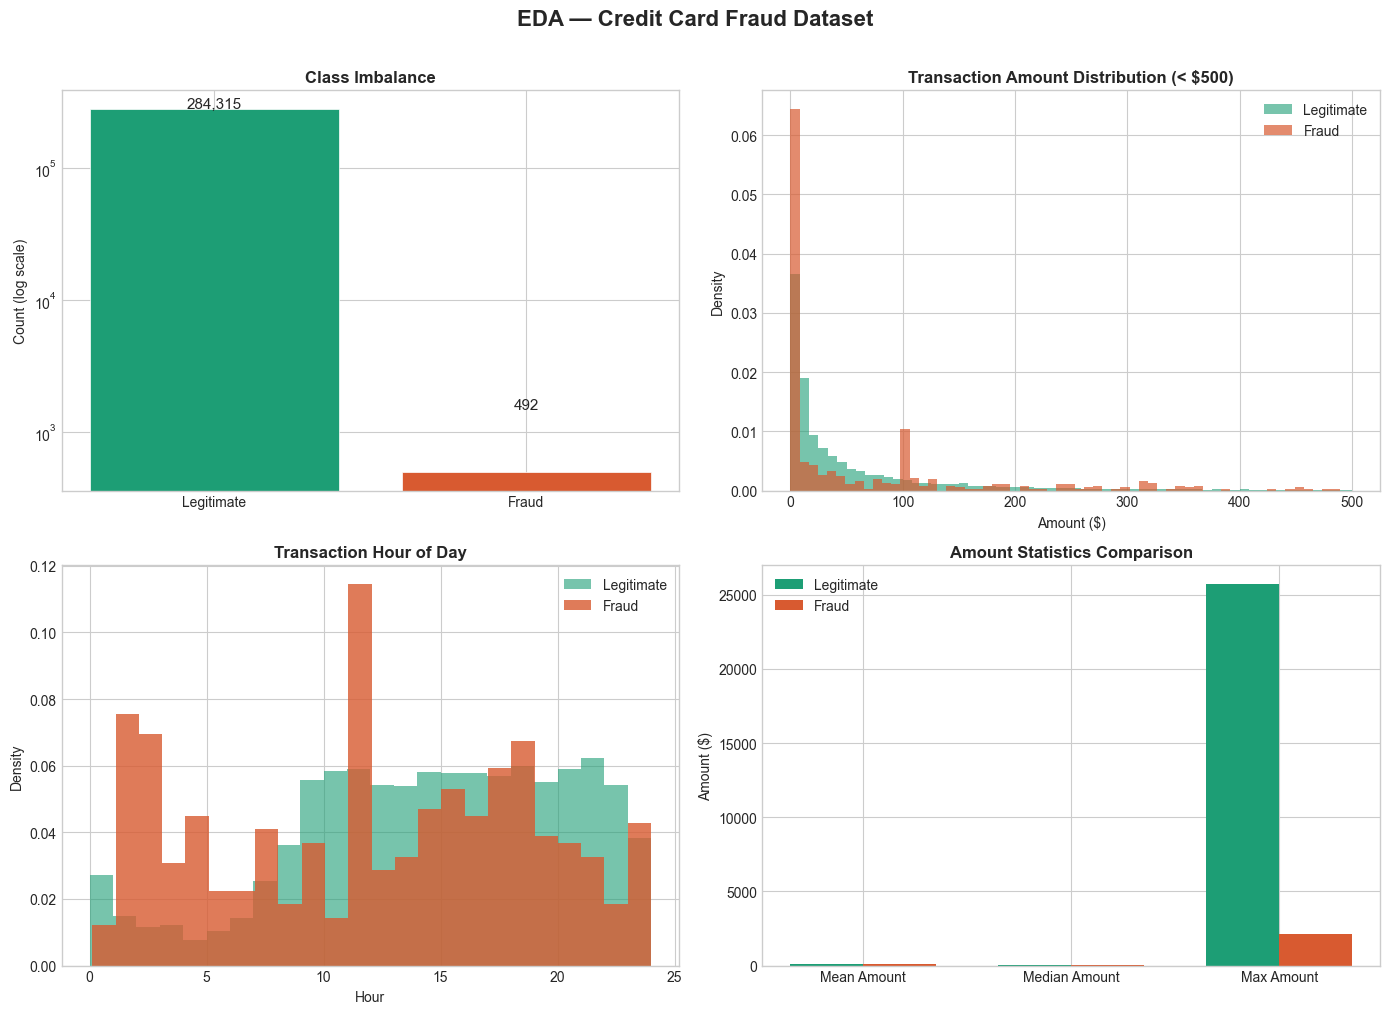


Mean fraud amount:  $122.21
Mean legit amount:  $88.29
Fraud txns at night (0-6h): 124 / 492


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('EDA — Credit Card Fraud Dataset', fontsize=16, fontweight='bold', y=1.01)

# 1. Class imbalance bar
ax = axes[0, 0]
bars = ax.bar(['Legitimate', 'Fraud'], [vc[0], vc[1]],
              color=[PALETTE['legit'], PALETTE['fraud']], edgecolor='white', linewidth=0.5)
ax.set_title('Class Imbalance', fontweight='bold')
ax.set_ylabel('Number of transactions')
for bar, val in zip(bars, [vc[0], vc[1]]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1000,
            f'{val:,}', ha='center', fontsize=11)
ax.set_yscale('log')
ax.set_ylabel('Count (log scale)')

# 2. Transaction amount by class
ax = axes[0, 1]
legit_amt = df[df['Class']==0]['Amount']
fraud_amt = df[df['Class']==1]['Amount']
ax.hist(legit_amt[legit_amt < 500], bins=60, alpha=0.6,
        color=PALETTE['legit'], label='Legitimate', density=True)
ax.hist(fraud_amt[fraud_amt < 500], bins=60, alpha=0.7,
        color=PALETTE['fraud'], label='Fraud', density=True)
ax.set_title('Transaction Amount Distribution (< $500)', fontweight='bold')
ax.set_xlabel('Amount ($)')
ax.set_ylabel('Density')
ax.legend()

# 3. Time of day distribution
ax = axes[1, 0]
df['Hour'] = (df['Time'] / 3600) % 24
ax.hist(df[df['Class']==0]['Hour'], bins=24, alpha=0.6,
        color=PALETTE['legit'], label='Legitimate', density=True)
ax.hist(df[df['Class']==1]['Hour'], bins=24, alpha=0.8,
        color=PALETTE['fraud'], label='Fraud', density=True)
ax.set_title('Transaction Hour of Day', fontweight='bold')
ax.set_xlabel('Hour')
ax.set_ylabel('Density')
ax.legend()

# 4. Amount stats comparison
ax = axes[1, 1]
stats_data = pd.DataFrame({
    'Metric': ['Mean Amount', 'Median Amount', 'Max Amount'],
    'Legitimate': [legit_amt.mean(), legit_amt.median(), legit_amt.max()],
    'Fraud': [fraud_amt.mean(), fraud_amt.median(), fraud_amt.max()]
})
x = np.arange(3)
w = 0.35
ax.bar(x - w/2, stats_data['Legitimate'], w, color=PALETTE['legit'], label='Legitimate')
ax.bar(x + w/2, stats_data['Fraud'], w, color=PALETTE['fraud'], label='Fraud')
ax.set_xticks(x)
ax.set_xticklabels(stats_data['Metric'])
ax.set_title('Amount Statistics Comparison', fontweight='bold')
ax.set_ylabel('Amount ($)')
ax.legend()

plt.tight_layout()
plt.savefig('eda_overview.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'\nMean fraud amount:  ${fraud_amt.mean():.2f}')
print(f'Mean legit amount:  ${legit_amt.mean():.2f}')
print(f'Fraud txns at night (0-6h): {(df[(df["Class"]==1) & (df["Hour"]<6)].shape[0])} / {vc[1]}')

## Cell 4 — Phase 2: Feature Engineering + PCA

Feature matrix shape: (284807, 30)

Components to explain 95% variance: 22
PCA-reduced shape: (284807, 22)


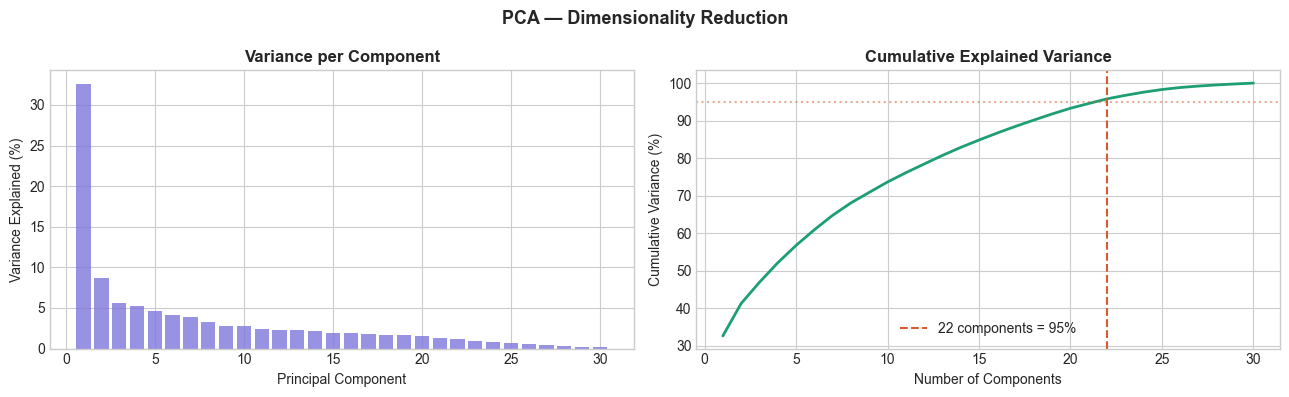

In [5]:
# ── Feature Engineering ──────────────────────────────────────────────────────
# Scale Amount and Time (V1-V28 are already PCA-transformed by the dataset)
scaler = RobustScaler()  # RobustScaler is better than StandardScaler for outlier-heavy data

df['Amount_scaled'] = scaler.fit_transform(df[['Amount']])
df['Time_scaled']   = scaler.fit_transform(df[['Time']])

# Feature matrix: V1-V28 + scaled Amount + scaled Time
feature_cols = [f'V{i}' for i in range(1, 29)] + ['Amount_scaled', 'Time_scaled']
X = df[feature_cols].values
y = df['Class'].values

print(f'Feature matrix shape: {X.shape}')

# ── PCA — reduce 30 features to top components ───────────────────────────────
pca_full = PCA(n_components=30)
pca_full.fit(X)

cumvar = np.cumsum(pca_full.explained_variance_ratio_)
n_components = np.argmax(cumvar >= 0.95) + 1
print(f'\nComponents to explain 95% variance: {n_components}')

# Apply PCA
pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X)
print(f'PCA-reduced shape: {X_pca.shape}')

# ── Plot explained variance ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(range(1, 31), pca_full.explained_variance_ratio_ * 100,
            color='#7F77DD', alpha=0.8)
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Variance Explained (%)')
axes[0].set_title('Variance per Component', fontweight='bold')

axes[1].plot(range(1, 31), cumvar * 100, color='#1D9E75', linewidth=2)
axes[1].axvline(n_components, color='#D85A30', linestyle='--', label=f'{n_components} components = 95%')
axes[1].axhline(95, color='#D85A30', linestyle=':', alpha=0.5)
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Variance (%)')
axes[1].set_title('Cumulative Explained Variance', fontweight='bold')
axes[1].legend()

plt.suptitle('PCA — Dimensionality Reduction', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('pca_variance.png', dpi=150, bbox_inches='tight')
plt.show()

## Cell 5 — Phase 3: Outlier Analysis (Z-Score + IQR)

── Outlier Detection Results ──────────────────────────
Total flagged:         31,904
Fraud in flagged:      91
Precision (of flags):  0.29%
Recall  (of frauds):   18.50%


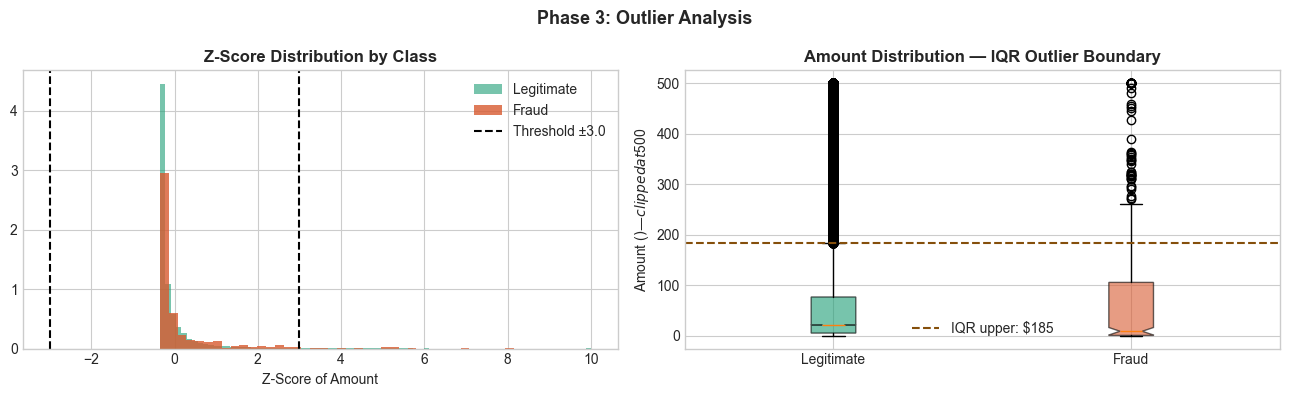

In [6]:
# ── Z-Score outlier flagging ──────────────────────────────────────────────────
from scipy.stats import zscore

df['Amount_zscore'] = zscore(df['Amount'])
ZSCORE_THRESH = 3.0
df['zscore_flag'] = (np.abs(df['Amount_zscore']) > ZSCORE_THRESH).astype(int)

# ── IQR outlier flagging ─────────────────────────────────────────────────────
Q1 = df['Amount'].quantile(0.25)
Q3 = df['Amount'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
df['iqr_flag'] = ((df['Amount'] < lower) | (df['Amount'] > upper)).astype(int)

# ── Combined flag ────────────────────────────────────────────────────────────
df['outlier_flag'] = ((df['zscore_flag'] == 1) | (df['iqr_flag'] == 1)).astype(int)

# ── Evaluation: how many flagged are actually fraud? ─────────────────────────
flagged = df[df['outlier_flag'] == 1]
precision_outlier = flagged['Class'].mean()
recall_outlier = df[df['Class']==1]['outlier_flag'].mean()

print('── Outlier Detection Results ──────────────────────────')
print(f'Total flagged:         {flagged.shape[0]:,}')
print(f'Fraud in flagged:      {flagged["Class"].sum():,}')
print(f'Precision (of flags):  {precision_outlier:.2%}')
print(f'Recall  (of frauds):   {recall_outlier:.2%}')

# ── Visualization ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Z-score distribution
ax = axes[0]
ax.hist(df[df['Class']==0]['Amount_zscore'].clip(-5, 10), bins=80,
        alpha=0.6, color=PALETTE['legit'], label='Legitimate', density=True)
ax.hist(df[df['Class']==1]['Amount_zscore'].clip(-5, 10), bins=40,
        alpha=0.8, color=PALETTE['fraud'], label='Fraud', density=True)
ax.axvline(ZSCORE_THRESH, color='black', linestyle='--', linewidth=1.5, label=f'Threshold ±{ZSCORE_THRESH}')
ax.axvline(-ZSCORE_THRESH, color='black', linestyle='--', linewidth=1.5)
ax.set_title('Z-Score Distribution by Class', fontweight='bold')
ax.set_xlabel('Z-Score of Amount')
ax.legend()

# Box plot
ax = axes[1]
data_box = [df[df['Class']==0]['Amount'].clip(0, 500),
            df[df['Class']==1]['Amount'].clip(0, 500)]
try:
    bp = ax.boxplot(data_box, tick_labels=['Legitimate', 'Fraud'],
                    patch_artist=True, notch=True)
except TypeError:  # older matplotlib
    bp = ax.boxplot(data_box, labels=['Legitimate', 'Fraud'],
                    patch_artist=True, notch=True)
bp['boxes'][0].set_facecolor(PALETTE['legit'])
bp['boxes'][1].set_facecolor(PALETTE['fraud'])
for patch in bp['boxes']:
    patch.set_alpha(0.6)
ax.axhline(upper, color='#854F0B', linestyle='--', linewidth=1.5, label=f'IQR upper: ${upper:.0f}')
ax.set_title('Amount Distribution — IQR Outlier Boundary', fontweight='bold')
ax.set_ylabel('Amount ($) — clipped at $500')
ax.legend()

plt.suptitle('Phase 3: Outlier Analysis', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('outlier_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## Cell 6 — Phase 3b: K-Means Clustering

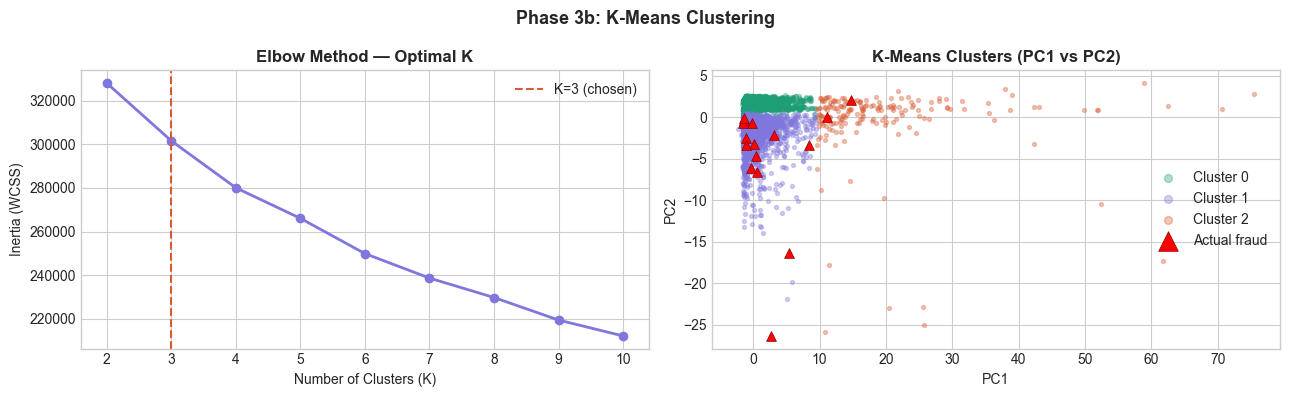


── Fraud Rate per Cluster ─────────────────────────────
         total  fraud_count  fraud_rate
cluster                                
2          181            2    0.011050
1         5194           13    0.002503
0         4625            1    0.000216

→ Suspect cluster: Cluster 2 (fraud rate: 1.10%)


In [7]:
# ── Find optimal K using Elbow method ────────────────────────────────────────
# Use a sample for speed (K-Means on 284k rows is slow)
SAMPLE_N = 10000
sample_idx = np.random.choice(len(X_pca), SAMPLE_N, replace=False)
X_sample = X_pca[sample_idx]
y_sample = y[sample_idx]

inertias = []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_sample)
    inertias.append(km.inertia_)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Elbow plot
axes[0].plot(K_range, inertias, 'o-', color='#7F77DD', linewidth=2, markersize=6)
axes[0].axvline(3, color='#D85A30', linestyle='--', label='K=3 (chosen)')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia (WCSS)')
axes[0].set_title('Elbow Method — Optimal K', fontweight='bold')
axes[0].legend()

# ── Fit final K-Means with K=3 ───────────────────────────────────────────────
K = 3
kmeans = KMeans(n_clusters=K, random_state=42, n_init=20, max_iter=300)
cluster_labels = kmeans.fit_predict(X_sample)

# Visualize in PCA space (PC1 vs PC2)
ax = axes[1]
cluster_colors = ['#1D9E75', '#7F77DD', '#D85A30']
for c in range(K):
    mask = cluster_labels == c
    ax.scatter(X_sample[mask, 0], X_sample[mask, 1],
               color=cluster_colors[c], alpha=0.35, s=8, label=f'Cluster {c}')

# Overlay actual fraud in red
fraud_mask = y_sample == 1
ax.scatter(X_sample[fraud_mask, 0], X_sample[fraud_mask, 1],
           color='red', marker='^', s=50, zorder=5,
           label='Actual fraud', edgecolors='darkred', linewidths=0.5)

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_title('K-Means Clusters (PC1 vs PC2)', fontweight='bold')
ax.legend(markerscale=2)

plt.suptitle('Phase 3b: K-Means Clustering', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('kmeans_clusters.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Fraud rate per cluster ───────────────────────────────────────────────────
print('\n── Fraud Rate per Cluster ─────────────────────────────')
df_cluster = pd.DataFrame({'cluster': cluster_labels, 'actual_fraud': y_sample})
cluster_stats = df_cluster.groupby('cluster').agg(
    total=('actual_fraud','count'),
    fraud_count=('actual_fraud','sum')
)
cluster_stats['fraud_rate'] = cluster_stats['fraud_count'] / cluster_stats['total']
print(cluster_stats.sort_values('fraud_rate', ascending=False))

suspect_cluster = cluster_stats['fraud_rate'].idxmax()
print(f'\n→ Suspect cluster: Cluster {suspect_cluster} '
      f'(fraud rate: {cluster_stats.loc[suspect_cluster,"fraud_rate"]:.2%})')

## Cell 7 — Phase 4: Hypothesis Testing (Mann-Whitney U Test)

── Hypothesis Test Results ────────────────────────────────
H0: Mean transaction amount is the same across clusters
H1: Suspect cluster has significantly different amounts

Mann-Whitney U statistic: 1775292.50
Mann-Whitney p-value:     1.82e-117  → REJECT H0 ✅

T-test statistic:         117.57
T-test p-value:           0.00e+00  → REJECT H0 ✅

Cohen's d (effect size):  2.3071  → Large effect

Suspect cluster — Mean amount:  $1375.95
Normal clusters — Mean amount:  $62.75


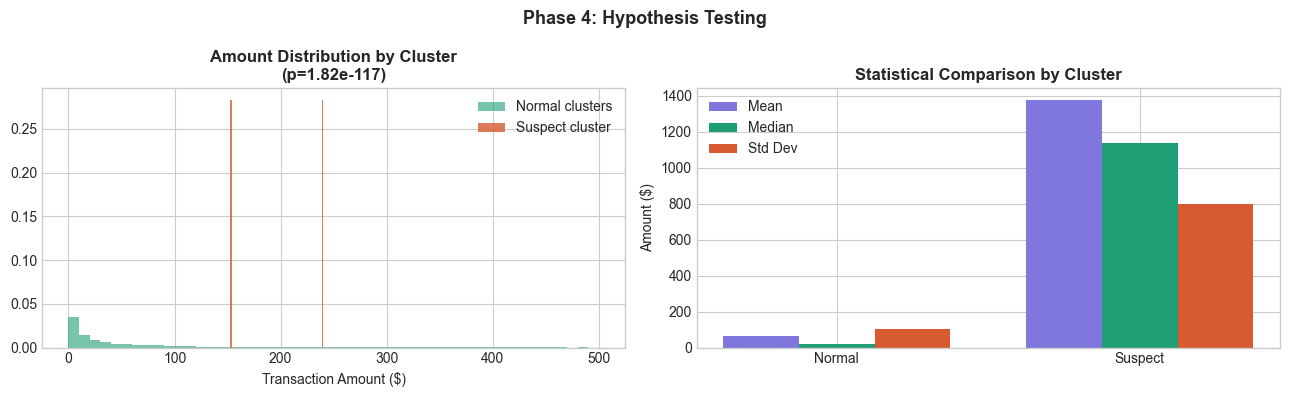

In [8]:
# ── Mann-Whitney U Test: Does fraud cluster have different amounts? ───────────
# Non-parametric — better than t-test for skewed financial data

suspect_mask = cluster_labels == suspect_cluster
normal_mask  = ~suspect_mask

suspect_amounts = df['Amount'].values[sample_idx][suspect_mask]
normal_amounts  = df['Amount'].values[sample_idx][normal_mask]

stat_mw, p_mw = mannwhitneyu(suspect_amounts, normal_amounts, alternative='two-sided')
stat_t,  p_t  = ttest_ind(suspect_amounts, normal_amounts)

# Cohen's d (effect size)
pooled_std = np.sqrt((suspect_amounts.std()**2 + normal_amounts.std()**2) / 2)
cohens_d = (suspect_amounts.mean() - normal_amounts.mean()) / pooled_std

print('── Hypothesis Test Results ────────────────────────────────')
print(f'H0: Mean transaction amount is the same across clusters')
print(f'H1: Suspect cluster has significantly different amounts')
print()
print(f'Mann-Whitney U statistic: {stat_mw:.2f}')
print(f'Mann-Whitney p-value:     {p_mw:.2e}  → {"REJECT H0 ✅" if p_mw < 0.05 else "Fail to reject H0"}')
print()
print(f'T-test statistic:         {stat_t:.2f}')
print(f'T-test p-value:           {p_t:.2e}  → {"REJECT H0 ✅" if p_t < 0.05 else "Fail to reject H0"}')
print()
print(f"Cohen's d (effect size):  {cohens_d:.4f}  → {'Large' if abs(cohens_d)>0.8 else 'Medium' if abs(cohens_d)>0.5 else 'Small'} effect")
print()
print(f'Suspect cluster — Mean amount:  ${suspect_amounts.mean():.2f}')
print(f'Normal clusters — Mean amount:  ${normal_amounts.mean():.2f}')

# ── Visualization ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.hist(normal_amounts[normal_amounts < 500], bins=50,
        alpha=0.6, color=PALETTE['legit'], label='Normal clusters', density=True)
ax.hist(suspect_amounts[suspect_amounts < 500], bins=50,
        alpha=0.8, color=PALETTE['fraud'], label='Suspect cluster', density=True)
ax.set_title(f'Amount Distribution by Cluster\n(p={p_mw:.2e})', fontweight='bold')
ax.set_xlabel('Transaction Amount ($)')
ax.legend()

ax = axes[1]
stats_df = pd.DataFrame({
    'Cluster': ['Normal', 'Suspect'],
    'Mean':   [normal_amounts.mean(), suspect_amounts.mean()],
    'Median': [np.median(normal_amounts), np.median(suspect_amounts)],
    'Std':    [normal_amounts.std(), suspect_amounts.std()]
})
x = np.arange(2)
w = 0.25
ax.bar(x - w, stats_df['Mean'],   w, color='#7F77DD', label='Mean')
ax.bar(x,     stats_df['Median'], w, color='#1D9E75', label='Median')
ax.bar(x + w, stats_df['Std'],    w, color='#D85A30', label='Std Dev')
ax.set_xticks(x)
ax.set_xticklabels(stats_df['Cluster'])
ax.set_ylabel('Amount ($)')
ax.set_title('Statistical Comparison by Cluster', fontweight='bold')
ax.legend()

plt.suptitle('Phase 4: Hypothesis Testing', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('hypothesis_testing.png', dpi=150, bbox_inches='tight')
plt.show()

## Cell 8 — Phase 5: Handle Class Imbalance with SMOTE

Before SMOTE:
  Train shape: (227845, 30) | Fraud: 394 (0.173%)
  Test shape:  (56962, 30)  | Fraud: 98 (0.172%)

After SMOTE (training only):
  Train shape: (454902, 30) | Fraud: 227,451 (50.0%)
  ⚠️  Test set is NEVER touched by SMOTE — evaluation stays realistic


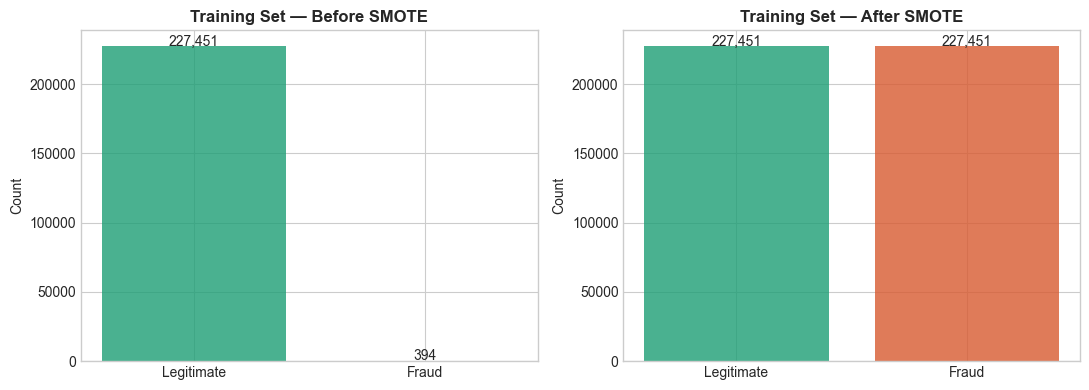

In [9]:
# ── Train/Test Split (stratified to preserve fraud ratio) ────────────────────
idx_train, idx_test = train_test_split(
    np.arange(len(df)), test_size=0.2, random_state=42, stratify=y
)
X_train, X_test = X[idx_train], X[idx_test]
y_train, y_test = y[idx_train], y[idx_test]

print('Before SMOTE:')
print(f'  Train shape: {X_train.shape} | Fraud: {y_train.sum():,} ({y_train.mean():.3%})')
print(f'  Test shape:  {X_test.shape}  | Fraud: {y_test.sum():,} ({y_test.mean():.3%})')

# ── Apply SMOTE only to training data ────────────────────────────────────────
smote = SMOTE(random_state=42, k_neighbors=5)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print('\nAfter SMOTE (training only):')
print(f'  Train shape: {X_train_sm.shape} | Fraud: {y_train_sm.sum():,} ({y_train_sm.mean():.1%})')
print('  ⚠️  Test set is NEVER touched by SMOTE — evaluation stays realistic')

# Visualize before/after
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (data, label) in zip(axes, [(y_train, 'Before SMOTE'), (y_train_sm, 'After SMOTE')]):
    vc_ = pd.Series(data).value_counts()
    ax.bar(['Legitimate', 'Fraud'], [vc_[0], vc_[1]],
           color=[PALETTE['legit'], PALETTE['fraud']], alpha=0.8)
    ax.set_title(f'Training Set — {label}', fontweight='bold')
    ax.set_ylabel('Count')
    for i, v in enumerate([vc_[0], vc_[1]]):
        ax.text(i, v + 500, f'{v:,}', ha='center')

plt.tight_layout()
plt.savefig('smote_balance.png', dpi=150, bbox_inches='tight')
plt.show()

## Cell 9 — Phase 5a: Logistic Regression

Training Logistic Regression...

── Logistic Regression Results ────────────────────────────
              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.99     56864
       Fraud       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962

ROC-AUC:  0.9712
F1-Score (fraud): 0.1106

5-Fold CV ROC-AUC: 0.9802 ± 0.0123


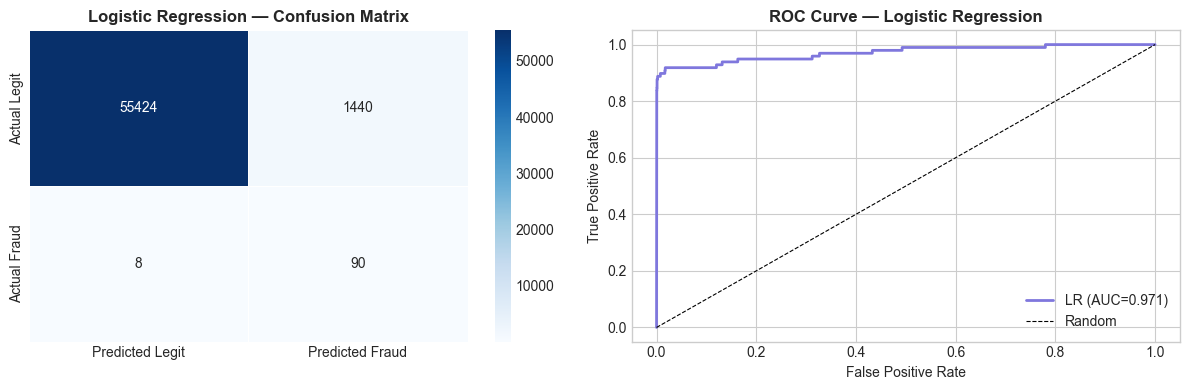

In [10]:
print('Training Logistic Regression...')
lr = LogisticRegression(
    C=0.1,
    solver='lbfgs',
    max_iter=1000,
    random_state=42,
    class_weight='balanced'  # extra safety net on top of SMOTE
)
lr.fit(X_train_sm, y_train_sm)

y_pred_lr  = lr.predict(X_test)
y_prob_lr  = lr.predict_proba(X_test)[:, 1]

print('\n── Logistic Regression Results ────────────────────────────')
print(classification_report(y_test, y_pred_lr, target_names=['Legitimate', 'Fraud']))
print(f'ROC-AUC:  {roc_auc_score(y_test, y_prob_lr):.4f}')
print(f'F1-Score (fraud): {f1_score(y_test, y_pred_lr):.4f}')

# Cross-validation (leak-free: SMOTE is applied inside each training fold only,
# and validation folds stay real/imbalanced)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_pipe = ImbPipeline([
    ('smote', SMOTE(random_state=42, k_neighbors=5)),
    ('lr', LogisticRegression(C=0.1, solver='lbfgs', max_iter=1000,
                              random_state=42, class_weight='balanced'))
])
cv_scores = cross_val_score(cv_pipe, X_train, y_train, cv=cv, scoring='roc_auc')
print(f'\n5-Fold CV ROC-AUC: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}')

# ── Confusion matrix ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cm = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Legit', 'Predicted Fraud'],
            yticklabels=['Actual Legit', 'Actual Fraud'],
            ax=axes[0], linewidths=0.5)
axes[0].set_title('Logistic Regression — Confusion Matrix', fontweight='bold')

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob_lr)
auc_lr = roc_auc_score(y_test, y_prob_lr)
axes[1].plot(fpr, tpr, color='#7F77DD', linewidth=2, label=f'LR (AUC={auc_lr:.3f})')
axes[1].plot([0,1],[0,1], 'k--', linewidth=0.8, label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve — Logistic Regression', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.savefig('logistic_regression_results.png', dpi=150, bbox_inches='tight')
plt.show()

## Cell 10 — Phase 5b: SVM Classifier

In [11]:
# SVM on full data is very slow — use a balanced sample
# Take all fraud + equal number of legit from SMOTE-balanced train
SVM_SAMPLE = 20000
idx_fraud  = np.where(y_train_sm == 1)[0]
idx_legit  = np.where(y_train_sm == 0)[0][:SVM_SAMPLE // 2]
idx_svm    = np.concatenate([idx_fraud[:SVM_SAMPLE // 2], idx_legit])
np.random.shuffle(idx_svm)

X_svm = X_train_sm[idx_svm]
y_svm = y_train_sm[idx_svm]

print(f'SVM training sample: {X_svm.shape[0]:,} rows | Fraud: {y_svm.sum():,}')
print('Training SVM (RBF kernel)... this may take ~1-2 minutes')

svm = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    probability=True,   # needed for ROC-AUC
    class_weight='balanced',
    random_state=42
)
svm.fit(X_svm, y_svm)

y_pred_svm = svm.predict(X_test)
y_prob_svm = svm.predict_proba(X_test)[:, 1]

print('\n── SVM Results ─────────────────────────────────────────────')
print(classification_report(y_test, y_pred_svm, target_names=['Legitimate', 'Fraud']))
print(f'ROC-AUC:  {roc_auc_score(y_test, y_prob_svm):.4f}')
print(f'F1-Score (fraud): {f1_score(y_test, y_pred_svm):.4f}')

SVM training sample: 20,000 rows | Fraud: 10,000
Training SVM (RBF kernel)... this may take ~1-2 minutes

── SVM Results ─────────────────────────────────────────────
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     56864
       Fraud       0.09      0.92      0.16        98

    accuracy                           0.98     56962
   macro avg       0.54      0.95      0.57     56962
weighted avg       1.00      0.98      0.99     56962

ROC-AUC:  0.9802
F1-Score (fraud): 0.1567


## Cell 11 — Phase 6: Final Model Comparison & Evaluation

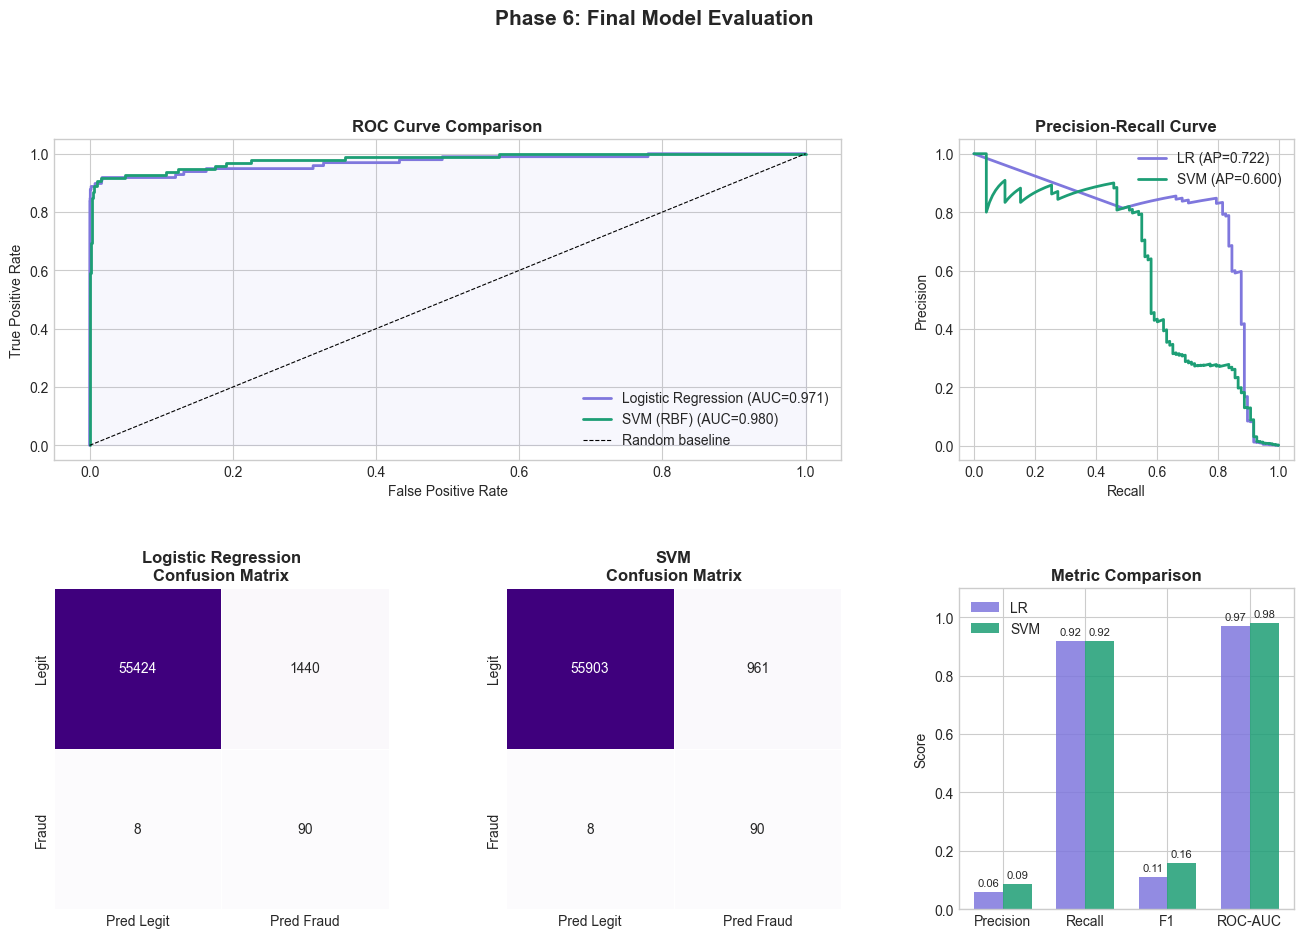


── Final Summary ───────────────────────────────────────────
Model                      Precision     Recall         F1    ROC-AUC
-----------------------------------------------------------------
Logistic Regression           0.0588     0.9184     0.1106     0.9712
SVM (RBF)                     0.0856     0.9184     0.1567     0.9802


In [12]:
fig = plt.figure(figsize=(16, 10))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.4, wspace=0.35)

# ── 1. ROC curves side by side ───────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, :2])
for name, y_prob, color in [
    ('Logistic Regression', y_prob_lr,  '#7F77DD'),
    ('SVM (RBF)',           y_prob_svm, '#1D9E75'),
]:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    ax1.plot(fpr, tpr, color=color, linewidth=2, label=f'{name} (AUC={auc:.3f})')
ax1.plot([0,1],[0,1],'k--', linewidth=0.8, label='Random baseline')
ax1.fill_between(fpr, tpr, alpha=0.06, color='#7F77DD')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('ROC Curve Comparison', fontweight='bold')
ax1.legend(loc='lower right')

# ── 2. Precision-Recall curves ───────────────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 2])
for name, y_prob, color in [
    ('LR',  y_prob_lr,  '#7F77DD'),
    ('SVM', y_prob_svm, '#1D9E75'),
]:
    prec, rec, _ = precision_recall_curve(y_test, y_prob)
    ap = average_precision_score(y_test, y_prob)
    ax2.plot(rec, prec, color=color, linewidth=2, label=f'{name} (AP={ap:.3f})')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.set_title('Precision-Recall Curve', fontweight='bold')
ax2.legend()

# ── 3. Confusion matrices ────────────────────────────────────────────────────
for col, (name, y_pred) in enumerate([
    ('Logistic Regression', y_pred_lr),
    ('SVM', y_pred_svm)
]):
    ax = fig.add_subplot(gs[1, col])
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
                xticklabels=['Pred Legit', 'Pred Fraud'],
                yticklabels=['Legit', 'Fraud'],
                ax=ax, linewidths=0.5, cbar=False)
    ax.set_title(f'{name}\nConfusion Matrix', fontweight='bold')

# ── 4. Metrics bar chart ─────────────────────────────────────────────────────
ax4 = fig.add_subplot(gs[1, 2])
metrics = ['Precision', 'Recall', 'F1', 'ROC-AUC']
lr_vals  = [
    precision_score(y_test, y_pred_lr),
    recall_score(y_test, y_pred_lr),
    f1_score(y_test, y_pred_lr),
    roc_auc_score(y_test, y_prob_lr)
]
svm_vals = [
    precision_score(y_test, y_pred_svm),
    recall_score(y_test, y_pred_svm),
    f1_score(y_test, y_pred_svm),
    roc_auc_score(y_test, y_prob_svm)
]
x = np.arange(len(metrics))
w = 0.35
ax4.bar(x - w/2, lr_vals,  w, color='#7F77DD', label='LR',  alpha=0.85)
ax4.bar(x + w/2, svm_vals, w, color='#1D9E75', label='SVM', alpha=0.85)
ax4.set_xticks(x)
ax4.set_xticklabels(metrics)
ax4.set_ylim(0, 1.1)
ax4.set_ylabel('Score')
ax4.set_title('Metric Comparison', fontweight='bold')
ax4.legend()
for i, (lv, sv) in enumerate(zip(lr_vals, svm_vals)):
    ax4.text(i - w/2, lv + 0.02, f'{lv:.2f}', ha='center', fontsize=8)
    ax4.text(i + w/2, sv + 0.02, f'{sv:.2f}', ha='center', fontsize=8)

plt.suptitle('Phase 6: Final Model Evaluation', fontsize=15, fontweight='bold', y=1.01)
plt.savefig('final_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n── Final Summary ───────────────────────────────────────────')
print(f'{"Model":<25} {"Precision":>10} {"Recall":>10} {"F1":>10} {"ROC-AUC":>10}')
print('-' * 65)
print(f'{"Logistic Regression":<25} {lr_vals[0]:>10.4f} {lr_vals[1]:>10.4f} {lr_vals[2]:>10.4f} {lr_vals[3]:>10.4f}')
print(f'{"SVM (RBF)":<25} {svm_vals[0]:>10.4f} {svm_vals[1]:>10.4f} {svm_vals[2]:>10.4f} {svm_vals[3]:>10.4f}')

## Cell 12 — Bonus: Risk Scoring Output (What a Real System Looks Like)

── Sample Risk Scores (top 20 by fraud probability) ───────
 amount  ensemble_score    risk_tier  actual_fraud
   1.18             1.0 HIGH — Block             1
 112.33             1.0 HIGH — Block             1
 238.90             1.0 HIGH — Block             1
   1.00             1.0 HIGH — Block             1
  89.99             1.0 HIGH — Block             0
 120.54             1.0 HIGH — Block             1
  45.64             1.0 HIGH — Block             1
   1.00             1.0 HIGH — Block             1
  60.60             1.0 HIGH — Block             1
   1.00             1.0 HIGH — Block             1
   1.00             1.0 HIGH — Block             1
  89.99             1.0 HIGH — Block             0
   1.00             1.0 HIGH — Block             1
  94.82             1.0 HIGH — Block             1
   1.10             1.0 HIGH — Block             1
   1.00             1.0 HIGH — Block             1
   1.00             1.0 HIGH — Block             1
  89.99             1.

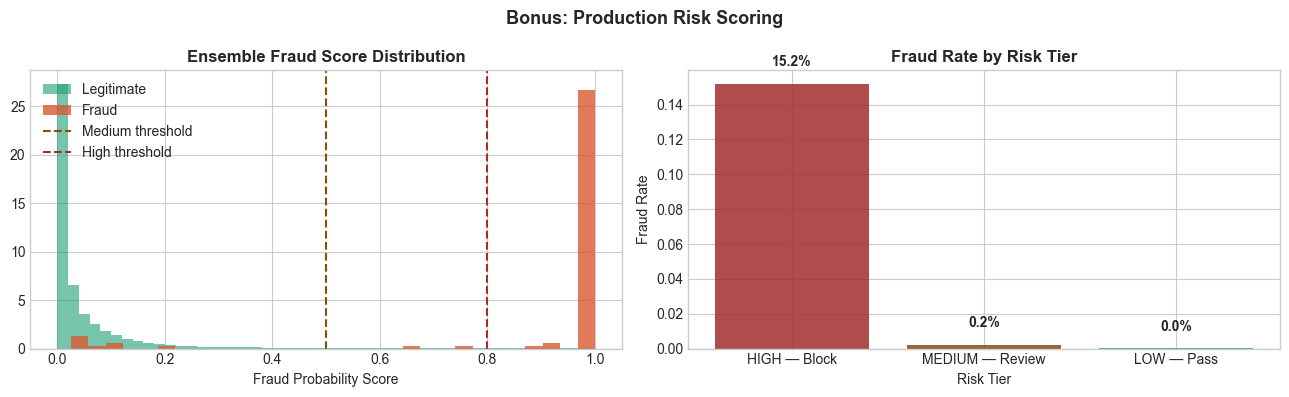


✅ Project complete! Saved plots: eda_overview.png, pca_variance.png,
   outlier_analysis.png, kmeans_clusters.png, hypothesis_testing.png,
   smote_balance.png, logistic_regression_results.png,
   final_model_comparison.png, risk_scoring.png


In [13]:
# ── Assign fraud probability score + risk tier to every test transaction ──────
risk_df = pd.DataFrame({
    'fraud_prob_lr':  y_prob_lr,
    'fraud_prob_svm': y_prob_svm,
    'ensemble_score': (y_prob_lr + y_prob_svm) / 2,
    'actual_fraud':   y_test,
    'amount':         df['Amount'].values[idx_test]
})

# NOTE: models were trained on SMOTE-balanced data, so probabilities are inflated.
# Tune these thresholds on a validation set before any real use.
def risk_tier(score):
    if score >= 0.80: return 'HIGH — Block'
    if score >= 0.50: return 'MEDIUM — Review'
    return 'LOW — Pass'

risk_df['risk_tier'] = risk_df['ensemble_score'].apply(risk_tier)

print('── Sample Risk Scores (top 20 by fraud probability) ───────')
print(risk_df.sort_values('ensemble_score', ascending=False).head(20)[
    ['amount', 'ensemble_score', 'risk_tier', 'actual_fraud']
].to_string(index=False))

print('\n── Risk Tier Distribution ─────────────────────────────────')
print(risk_df.groupby('risk_tier').agg(
    count=('actual_fraud','count'),
    fraud_caught=('actual_fraud','sum'),
    fraud_rate=('actual_fraud','mean')
).sort_values('fraud_rate', ascending=False))

# ── Visualize score distribution ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax = axes[0]
ax.hist(risk_df[risk_df['actual_fraud']==0]['ensemble_score'], bins=50,
        alpha=0.6, color=PALETTE['legit'], label='Legitimate', density=True)
ax.hist(risk_df[risk_df['actual_fraud']==1]['ensemble_score'], bins=30,
        alpha=0.8, color=PALETTE['fraud'], label='Fraud', density=True)
ax.axvline(0.5, color='#854F0B', linestyle='--', label='Medium threshold')
ax.axvline(0.8, color='#A32D2D', linestyle='--', label='High threshold')
ax.set_title('Ensemble Fraud Score Distribution', fontweight='bold')
ax.set_xlabel('Fraud Probability Score')
ax.legend()

ax = axes[1]
tier_fraud = risk_df.groupby('risk_tier')['actual_fraud'].mean().sort_values(ascending=False)
colors_t = ['#A32D2D', '#854F0B', '#1D9E75']
ax.bar(tier_fraud.index, tier_fraud.values, color=colors_t, alpha=0.85)
ax.set_title('Fraud Rate by Risk Tier', fontweight='bold')
ax.set_ylabel('Fraud Rate')
ax.set_xlabel('Risk Tier')
for i, v in enumerate(tier_fraud.values):
    ax.text(i, v + 0.01, f'{v:.1%}', ha='center', fontweight='bold')

plt.suptitle('Bonus: Production Risk Scoring', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('risk_scoring.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n✅ Project complete! Saved plots: eda_overview.png, pca_variance.png,')
print('   outlier_analysis.png, kmeans_clusters.png, hypothesis_testing.png,')
print('   smote_balance.png, logistic_regression_results.png,')
print('   final_model_comparison.png, risk_scoring.png')